## 1.Import Necessary Libraries

In [129]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
import seaborn as sns



## Import Dataset

In [3]:
cars_data = pd.read_csv(filepath_or_buffer="Cars.csv")
cars_data 

,HP,MPG,VOL,SP,WT
0,49,53.700681,89,104.185353,28.762059
1,55,50.013401,92,105.461264,30.466833
2,55,50.013401,92,105.461264,30.193597
3,70,45.696322,92,113.461264,30.632114
4,53,50.504232,92,104.461264,29.889149
...,...,...,...,...,...
76,322,36.900000,50,169.598513,16.132947
77,238,19.197888,115,150.576579,37.923113
78,263,34.000000,50,151.598513,15.769625
79,295,19.833733,119,167.944460,39.423099


## 3. Data Understanding

In [4]:
cars_data.shape

(81, 5)

In [6]:
cars_data.isnull().sum()

HP     0
MPG    0
VOL    0
SP     0
WT     0
dtype: int64

In [8]:
cars_data.dtypes

HP       int64
MPG    float64
VOL      int64
SP     float64
WT     float64
dtype: object

In [9]:
cars_data.describe()

,HP,MPG,VOL,SP,WT
count,81.000000,81.000000,81.000000,81.000000,81.000000
mean,117.469136,34.422076,98.765432,121.540272,32.412577
std,57.113502,9.131445,22.301497,14.181432,7.492813
min,49.000000,12.101263,50.000000,99.564907,15.712859
25%,84.000000,27.856252,89.000000,113.829145,29.591768
50%,100.000000,35.152727,101.000000,118.208698,32.734518
75%,140.000000,39.531633,113.000000,126.404312,37.392524
max,322.000000,53.700681,160.000000,169.598513,52.997752


## Now, let's check for the Assumptions

### Test 1: Linearity Test

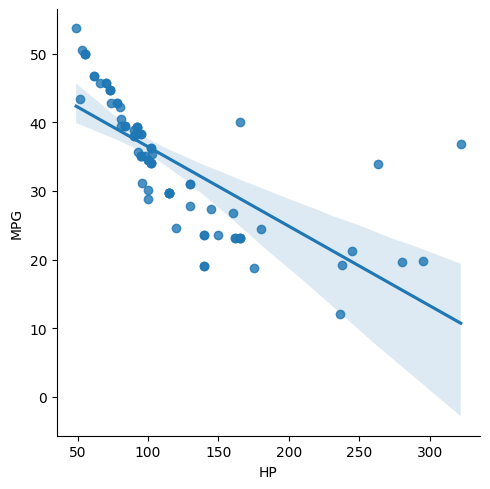

In [12]:
sns.lmplot(data = cars_data, x="HP", y="MPG")
plt.show()

### Test 1 Linearity Failed.

## Test 2: Normality Test

(array([15., 35.,  9.,  6.,  9.,  0.,  2.,  2.,  1.,  2.]),
 array([ 49. ,  76.3, 103.6, 130.9, 158.2, 185.5, 212.8, 240.1, 267.4,
        294.7, 322. ]),
 <BarContainer object of 10 artists>)

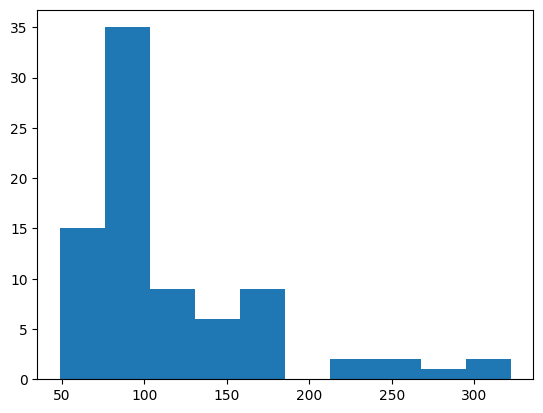

In [13]:
plt.hist(cars_data["HP"])

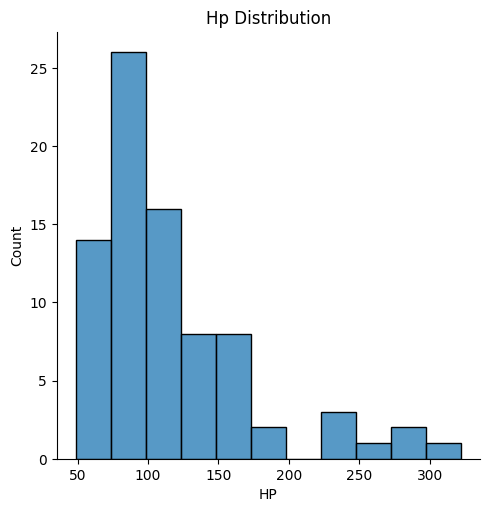

In [15]:
sns.displot(x=cars_data["HP"])
plt.title("Hp Distribution")
plt.show()

(array([ 9.,  0.,  0., 22., 19., 18.,  7.,  5.,  0.,  1.]),
 array([15.71285853, 19.44134791, 23.1698373 , 26.89832668, 30.62681606,
        34.35530544, 38.08379483, 41.81228421, 45.54077359, 49.26926298,
        52.99775236]),
 <BarContainer object of 10 artists>)

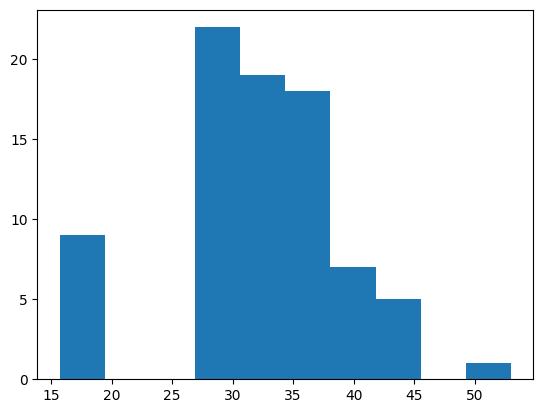

In [16]:
plt.hist(cars_data["WT"])

### Test 2: Normality also Filed

## Test 3: Multicollinearity Test

In [18]:
corr_matrix = cars_data.corr()
corr_matrix

,HP,MPG,VOL,SP,WT
HP,1.000000,-0.725038,0.077459,0.973848,0.076513
MPG,-0.725038,1.000000,-0.529057,-0.687125,-0.526759
VOL,0.077459,-0.529057,1.000000,0.102170,0.999203
SP,0.973848,-0.687125,0.102170,1.000000,0.102439
WT,0.076513,-0.526759,0.999203,0.102439,1.000000


<Axes: >

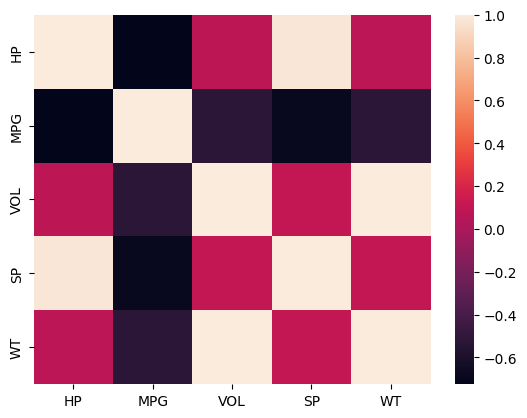

In [20]:
sns.heatmap(data = corr_matrix)

### Test 3: There is Multicollinearity in the Data

### Test 4: AutoRegression Passed

##  4. Data Preparation

In [21]:
cars_data

,HP,MPG,VOL,SP,WT
0,49,53.700681,89,104.185353,28.762059
1,55,50.013401,92,105.461264,30.466833
2,55,50.013401,92,105.461264,30.193597
3,70,45.696322,92,113.461264,30.632114
4,53,50.504232,92,104.461264,29.889149
...,...,...,...,...,...
76,322,36.900000,50,169.598513,16.132947
77,238,19.197888,115,150.576579,37.923113
78,263,34.000000,50,151.598513,15.769625
79,295,19.833733,119,167.944460,39.423099


In [107]:
X = cars_data[["HP","VOL","SP","WT"]]
X

,HP,VOL,SP,WT
0,49,89,104.185353,28.762059
1,55,92,105.461264,30.466833
2,55,92,105.461264,30.193597
3,70,92,113.461264,30.632114
4,53,92,104.461264,29.889149
...,...,...,...,...
76,322,50,169.598513,16.132947
77,238,115,150.576579,37.923113
78,263,50,151.598513,15.769625
79,295,119,167.944460,39.423099


In [108]:
y = cars_data["MPG"]
y

0     53.700681
1     50.013401
2     50.013401
3     45.696322
4     50.504232
        ...    
76    36.900000
77    19.197888
78    34.000000
79    19.833733
80    12.101263
Name: MPG, Length: 81, dtype: float64

### There is nothing to prepare because all features are numeric.

### 5. Model Building

In [109]:
linear_model = LinearRegression()
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, shuffle=True, random_state=42)
X_train

,HP,VOL,SP,WT
61,120,116,117.668550,37.860411
55,130,124,126.404312,40.589068
40,95,113,116.392639,37.392524
9,80,94,115.645204,30.920154
64,150,121,128.128401,40.159482
...,...,...,...,...
20,92,99,119.105055,32.324650
60,145,111,130.208698,36.888153
71,162,135,133.415985,44.013139
14,66,89,108.185353,29.347279


##  6.Model Training

In [110]:
linear_model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [111]:
linear_model.coef_

array([-0.22051886, -0.53968773,  0.53363516,  0.94526434])

In [112]:
linear_model.intercept_

np.float64(17.725737079015556)

## 7.Model Testing

### Training Data

In [113]:
y_pred_train = linear_model.predict(X_train)
y_pred

array([37.89770285, 33.3023649 , 47.98605515, 42.17264802, 35.48165898,
       37.53950097, 33.31108154, 38.54286458, 26.47040896, 25.14188416,
       22.44206834, 26.0975912 , 34.84603989, 41.15094046, 39.95980269,
       26.13645315, 42.53835981, 35.81583602, 37.87127922, 39.5625144 ,
       35.37334971, 35.59393404, 18.717314  , 12.31661154, 24.39887199,
       28.76093817, 38.07998482, 38.24861192, 35.79651664, 28.56722621,
       42.38879289, 37.21630246, 39.27144845, 36.91805291, 27.52358579,
       23.6416178 , 42.32536062, 34.82541399, 35.9391722 , 36.2613377 ,
       41.52153227, 17.89904991, 36.35652478, 48.28120247, 37.50473376,
       37.35199705, 40.79122814, 28.3207133 , 21.28209598, 42.27934147,
       41.76632332, 36.00285298, 37.22361389, 41.6181448 , 15.55948057,
       33.21313413, 29.87685849, 38.78152504, 37.13919796, 34.2129755 ,
       38.57706414, 46.73870908, 39.93380662, 34.21826465])

### Test Data

In [114]:
y_pred_test = linear_model.predict(X_test)
y_pred_test

array([33.25194201, 41.67282126, 37.34571718, 36.03030532, 40.73634756,
       35.85831389, 40.68418569, 31.78859887, 40.38431601, 40.1859865 ,
       32.60787495, 34.54417128, 23.43464652, 36.52921002, 24.35546583,
       35.57247482, 17.15238303])

## 8.Model Evalution

### Training Accuracy

In [135]:
mae_train = mean_absolute_error(y_train, y_pred_train)
mse_train = mean_squared_error(y_train, y_pred_train)
rmse_train = np.sqrt(mse_train)
r2_train = r2_score(y_train, y_pred_train)

In [136]:
print("TRAINING RESULTS")
print("MAE :", mae_train)
print("MSE :", mse_train)
print("RMSE:", rmse_train)
print("R²  :", r2_train)

TRAINING RESULTS
MAE : 3.21229778288897
MSE : 17.409334022026655
RMSE: 4.172449403171554
R²  : 0.7741103982497511


# =========================
# Testing Evaluation
# =========================

In [138]:
mae_test = mean_absolute_error(y_test, y_pred_test)
mse_test = mean_squared_error(y_test, y_pred_test)
rmse_test = np.sqrt(mse_test)
r2_test = r2_score(y_test, y_pred_test)

In [139]:
print("\n TEST RESULT")
print("MAE:", mae_test)
print("MSE:", mse_test)
print("RMSE:", rmse_test)
print("R2 Score:", r2_test)


 TEST RESULT
MAE: 4.114450703773381
MSE: 31.96412148975976
RMSE: 5.6536821178555625
R2 Score: 0.6749527236507021


In [60]:
error = y - y_pred
error.mean()

np.float64(-4.495717926877177e-15)

In [70]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score

In [62]:
mean_absolute_error(y, y_pred) # same units

3.267968285420799

In [66]:
mean_squared_error(y, y_pred) # squared output units

18.897141152343107

In [69]:
root_mean_squared_error(y, y_pred) # Normalise the units

4.347084212704316

In [71]:
r2_score(y, y_pred)

0.7705372737359844

In [74]:
import statsmodels.formula.api as smf

In [77]:
linear_stats_model = smf.ols(formula= "MPG ~ HP+VOL+SP+WT", data = cars_data).fit()

In [82]:
print("R2 Score:", linear_stats_model.rsquared.round(2),"\nAdjusted R2 Score:",linear_stats_model.rsquared_adj.round(2))

R2 Score: 0.77 
Adjusted R2 Score: 0.76


### Let's now perfomr Test 5: Homoscedasticity Test

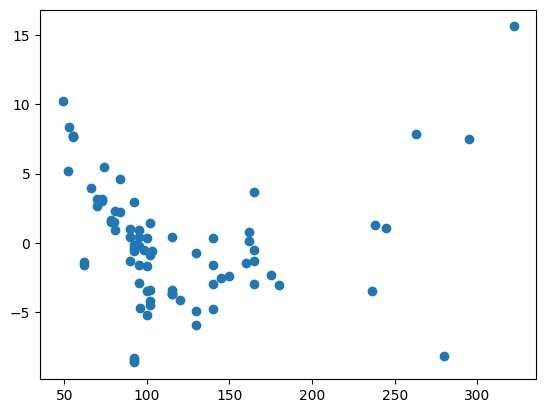

In [44]:
plt.scatter(data=cars_data, x="HP", y="error")

<Axes: xlabel='HP', ylabel='MPG'>

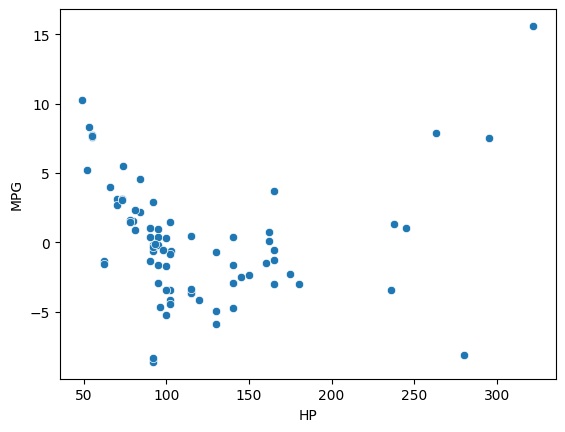

In [47]:
sns.scatterplot( data = cars_data, x = "HP", y = error)

### Test 5 Homoscedasticity Test also Failed

## Test 6: Zero Residual Mean Test

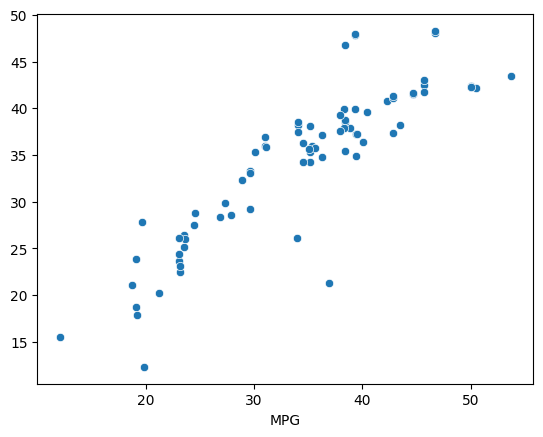

In [48]:
sns.scatterplot(x = cars_data["MPG"], y = y_pred)
plt.show()

### Test 6: Zero Residual Mean Test is also Failed

## 9. Model Deployment

In [49]:
from pickle import dump

In [50]:
dump(obj = linear_model, file = open(file = "linear_intelligence_file.pkl", mode= 'wb'))

In [55]:
from pickle import load
linear_intel_pkl = load(file = open(file = "linear_intelligence_file.pkl", mode='rb'))
linear_intel_pkl

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [57]:
linear_intel_pkl.predict(X)

array([43.44193477, 42.38879289, 42.27934147, 42.53835981, 42.17264802,
       43.02061916, 42.32536062, 48.07621852, 48.28120247, 40.79122814,
       41.52153227, 47.80956747, 39.95980269, 41.52757889, 41.76632332,
       41.6181448 , 41.15094046, 47.98605515, 41.30861046, 37.87127922,
       38.57706414, 37.35199705, 37.89770285, 39.5625144 , 39.93380662,
       46.73870908, 35.48165898, 38.78152504, 38.24861192, 36.00285298,
       34.84603989, 37.21630246, 37.13919796, 34.82541399, 37.22361389,
       37.53950097, 39.27144845, 38.24219888, 38.54286458, 35.9391722 ,
       34.2129755 , 35.36313259, 37.50473376, 38.07998482, 35.79651664,
       36.2613377 , 34.21826465, 35.59393404, 36.91805291, 33.31108154,
       33.21313413, 33.3023649 , 29.19864884, 27.52358579, 28.3207133 ,
       28.56722621, 35.81583602, 33.02108459, 35.37334971, 32.29909503,
       29.87685849, 28.76093817, 25.14188416, 26.47040896, 25.97651933,
       36.35652478, 26.0975912 , 23.6416178 , 24.39887199, 20.21